In [1]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from scipy.stats import loguniform, randint, uniform
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from inclusion_financiere.config import RANDOM_STATE, ROOT
from inclusion_financiere.data import get_train_test
from inclusion_financiere.evaluate import cv
from inclusion_financiere.pipeline import pipe
X_train, _, y_train, _ = get_train_test()


c:\Users\hp\Desktop\DATA SCIENTISTE AVEC FORCE N\AIMS_Programme\PROJET A RENDRE\AIMS-Module5_DS_ML_Oct-Nov-2026\inclusion-financiere\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
base = cross_val_score(
    pipe(LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)),
    X_train, y_train, cv=cv, scoring='average_precision',
)
base_mean, base_std = base.mean(), base.std()
print(f'Défaut : {base_mean:.4f} ± {base_std:.4f}')

Défaut : 0.5655 ± 0.0255


In [3]:
#Random Search (7.1)
espace = {
    'lgbmclassifier__learning_rate': loguniform(1e-3, 0.3),
    'lgbmclassifier__num_leaves': randint(4, 64),
    'lgbmclassifier__min_child_samples': randint(5, 200),
    'lgbmclassifier__subsample': uniform(0.5, 0.5), # entre 0,5 et 1
    'lgbmclassifier__subsample_freq': [1],
    'lgbmclassifier__colsample_bytree': uniform(0.5, 0.5),
    'lgbmclassifier__reg_lambda': loguniform(1e-3, 10),
    'lgbmclassifier__n_estimators': randint(100, 600),
}
t0 = time.perf_counter()
rs = RandomizedSearchCV(
    pipe(LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)),
    espace, n_iter=40, cv=cv, scoring='average_precision',
    random_state=RANDOM_STATE,
)
rs.fit(X_train, y_train)
temps_rs = time.perf_counter() - t0
print(rs.best_score_, rs.best_params_, f'{temps_rs:.0f} s')

0.5768207127096255 {'lgbmclassifier__colsample_bytree': np.float64(0.9211423872974993), 'lgbmclassifier__learning_rate': np.float64(0.013004555820744673), 'lgbmclassifier__min_child_samples': 194, 'lgbmclassifier__n_estimators': 583, 'lgbmclassifier__num_leaves': 17, 'lgbmclassifier__reg_lambda': np.float64(0.8111253665497066), 'lgbmclassifier__subsample': np.float64(0.6632703844029177), 'lgbmclassifier__subsample_freq': 1} 327 s


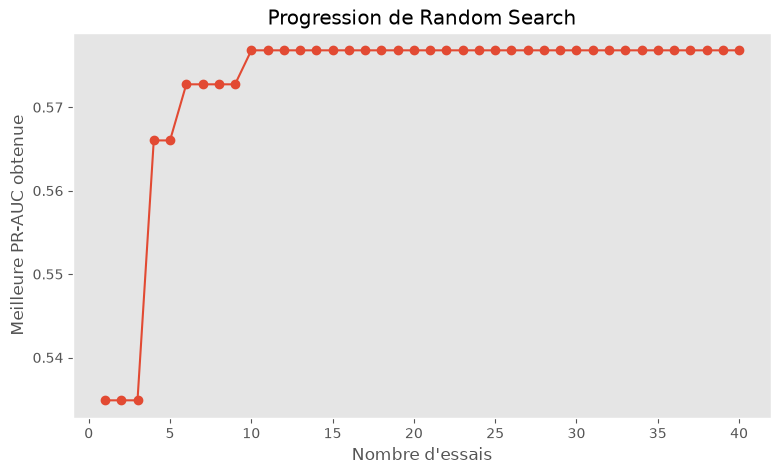

In [17]:
scores_rs = np.array(rs.cv_results_["mean_test_score"])

meilleur_rs_progressif = np.maximum.accumulate(scores_rs)

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(scores_rs) + 1),
    meilleur_rs_progressif,
    marker="o"
)

plt.xlabel("Nombre d'essais")
plt.ylabel("Meilleure PR-AUC obtenue")
plt.title("Progression de Random Search")
plt.grid()
plt.show()

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
        num_leaves=trial.suggest_int('num_leaves', 4, 64),
        min_child_samples=trial.suggest_int('min_child_samples', 5, 200, log=True),
        subsample=trial.suggest_float('subsample', 0.5, 1.0),
        subsample_freq=1,
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
        n_estimators=trial.suggest_int('n_estimators', 100, 600),
    )
    model = pipe(LGBMClassifier(**params, random_state=RANDOM_STATE, verbose=-1))
    return cross_val_score(
        model, X_train, y_train, cv=cv, scoring='average_precision'
    ).mean()

t0 = time.perf_counter()
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.optimize(objective, n_trials=40)

temps_optuna = time.perf_counter() - t0

print("Meilleure PR-AUC :", study.best_value)

print("\nMeilleurs paramètres :")
print(study.best_params)

print("\nTemps de calcul :", round(temps_optuna, 2), "secondes")

0.5806950131453987 {'learning_rate': 0.029341527565000736, 'num_leaves': 6, 'min_child_samples': 45, 'subsample': 0.5852620618436457, 'colsample_bytree': 0.5325257964926398, 'reg_lambda': 6.245139574743075, 'n_estimators': 583} 359 s
Meilleure PR-AUC : 0.5806950131453987

Meilleurs paramètres :
{'learning_rate': 0.029341527565000736, 'num_leaves': 6, 'min_child_samples': 45, 'subsample': 0.5852620618436457, 'colsample_bytree': 0.5325257964926398, 'reg_lambda': 6.245139574743075, 'n_estimators': 583}

Temps de calcul : 358.56 secondes


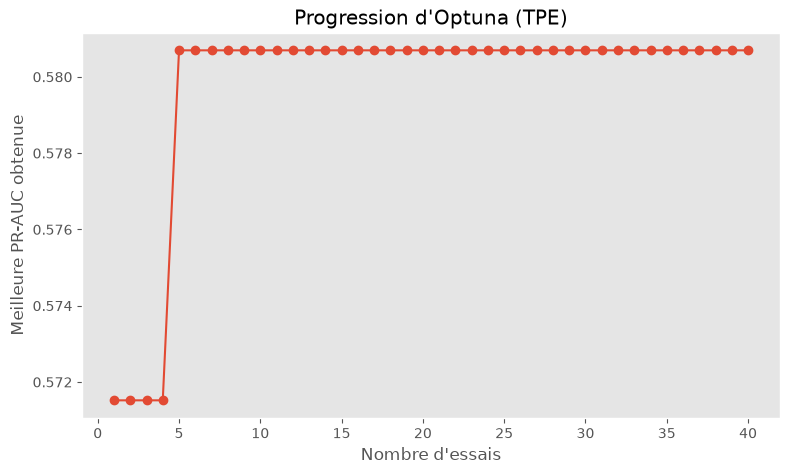

In [18]:
scores_optuna = [
    trial.value
    for trial in study.trials
    if trial.value is not None
]

meilleur_optuna_progressif = np.maximum.accumulate(
    scores_optuna
)

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(scores_optuna) + 1),
    meilleur_optuna_progressif,
    marker="o"
)

plt.xlabel("Nombre d'essais")
plt.ylabel("Meilleure PR-AUC obtenue")
plt.title("Progression d'Optuna (TPE)")
plt.grid()
plt.show()

In [ ]:
# le gain, en nombre d’écarts-types
for nom, score, t in [('Random Search', rs.best_score_, temps_rs),
                    ('Optuna', study.best_value, temps_optuna)]:
    print(f'{nom} : gain = {(score - base_mean) / base_std:.2f} écart-type, temps = {t:.0f} s')


,rank_test_score,mean_test_score,std_test_score,mean_fit_time,params
6,1,0.567418,0.027976,14.169514,"{'randomforestclassifier__bootstrap': True, 'r..."
30,2,0.566404,0.031018,6.061288,"{'randomforestclassifier__bootstrap': True, 'r..."
20,3,0.566385,0.027372,12.453305,"{'randomforestclassifier__bootstrap': True, 'r..."
16,4,0.565809,0.028914,4.452095,"{'randomforestclassifier__bootstrap': True, 'r..."
1,5,0.565798,0.030367,7.142294,"{'randomforestclassifier__bootstrap': True, 'r..."
9,6,0.565403,0.026907,4.434727,"{'randomforestclassifier__bootstrap': True, 'r..."
31,7,0.565372,0.027781,8.651522,"{'randomforestclassifier__bootstrap': True, 'r..."
21,8,0.564760,0.028820,12.570049,"{'randomforestclassifier__bootstrap': True, 'r..."
29,9,0.563168,0.031230,8.003187,"{'randomforestclassifier__bootstrap': True, 'r..."
15,10,0.562536,0.029908,3.911092,"{'randomforestclassifier__bootstrap': True, 'r..."


Fichier enregistré : C:\Users\hp\Desktop\DATA SCIENTISTE AVEC FORCE N\AIMS_Programme\PROJET A RENDRE\AIMS-Module5_DS_ML_Oct-Nov-2026\inclusion-financiere\reports\random_search_results.csv


In [16]:
resultats_optuna = study.trials_dataframe()

display(
    resultats_optuna.sort_values(
        "value",
        ascending=False
    ).head(10)
)


resultats_optuna.to_csv(
    ROOT /'reports' / "optuna_results.csv", index=False
)

print("Fichier enregistré :", ROOT /'reports' / "optuna_results.csv")

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_lambda,params_subsample,system_attrs_tpe:relative_params:0,state
4,4,0.580695,2026-11-10 16:31:12.976998,2026-11-10 16:31:22.451170,0 days 00:00:09.474172,0.532526,0.029342,45,583,6,6.245140,0.585262,NaN,COMPLETE
35,35,0.579934,2026-11-10 16:35:49.731190,2026-11-10 16:35:58.944829,0 days 00:00:09.213639,0.507575,0.011249,35,508,11,0.657870,0.587199,"{""colsample_bytree"": 0.5075746479909371, ""lear...",COMPLETE
25,25,0.579898,2026-11-10 16:34:40.035675,2026-11-10 16:34:47.513350,0 days 00:00:07.477675,0.559225,0.019647,78,448,9,1.883204,0.559517,"{""colsample_bytree"": 0.5592245143535576, ""lear...",COMPLETE
27,27,0.579442,2026-11-10 16:34:56.446881,2026-11-10 16:35:02.479798,0 days 00:00:06.032917,0.555910,0.046638,45,413,5,3.426250,0.514560,"{""colsample_bytree"": 0.5559100847862147, ""lear...",COMPLETE
9,9,0.579337,2026-11-10 16:32:05.405772,2026-11-10 16:32:15.977419,0 days 00:00:10.571647,0.901098,0.007651,35,594,21,0.001987,0.570462,NaN,COMPLETE
34,34,0.578939,2026-11-10 16:35:43.331802,2026-11-10 16:35:49.731190,0 days 00:00:06.399388,0.628083,0.072658,46,591,5,9.713741,0.539716,"{""colsample_bytree"": 0.6280832269607919, ""lear...",COMPLETE
37,37,0.578509,2026-11-10 16:36:07.269036,2026-11-10 16:36:15.374695,0 days 00:00:08.105659,0.569582,0.043263,35,512,6,9.831883,0.613619,"{""colsample_bytree"": 0.5695822269119718, ""lear...",COMPLETE
26,26,0.578366,2026-11-10 16:34:47.513350,2026-11-10 16:34:56.446881,0 days 00:00:08.933531,0.539638,0.036189,121,454,8,3.394040,0.593702,"{""colsample_bytree"": 0.5396381841022772, ""lear...",COMPLETE
16,16,0.578260,2026-11-10 16:33:15.470615,2026-11-10 16:33:23.098564,0 days 00:00:07.627949,0.534006,0.014772,66,491,20,0.037203,0.518212,"{""colsample_bytree"": 0.5340059214364012, ""lear...",COMPLETE
14,14,0.578149,2026-11-10 16:32:54.451207,2026-11-10 16:33:02.950941,0 days 00:00:08.499734,0.805996,0.030829,43,537,10,3.601185,0.554502,"{""colsample_bytree"": 0.8059962826368956, ""lear...",COMPLETE


Fichier enregistré : C:\Users\hp\Desktop\DATA SCIENTISTE AVEC FORCE N\AIMS_Programme\PROJET A RENDRE\AIMS-Module5_DS_ML_Oct-Nov-2026\inclusion-financiere\reports\optuna_results.csv


In [ ]:
import optuna.visualization.matplotlib as optuna_vis

optuna_vis.plot_optimization_history(study)

plt.title("Historique de l'optimisation Optuna")
plt.show()

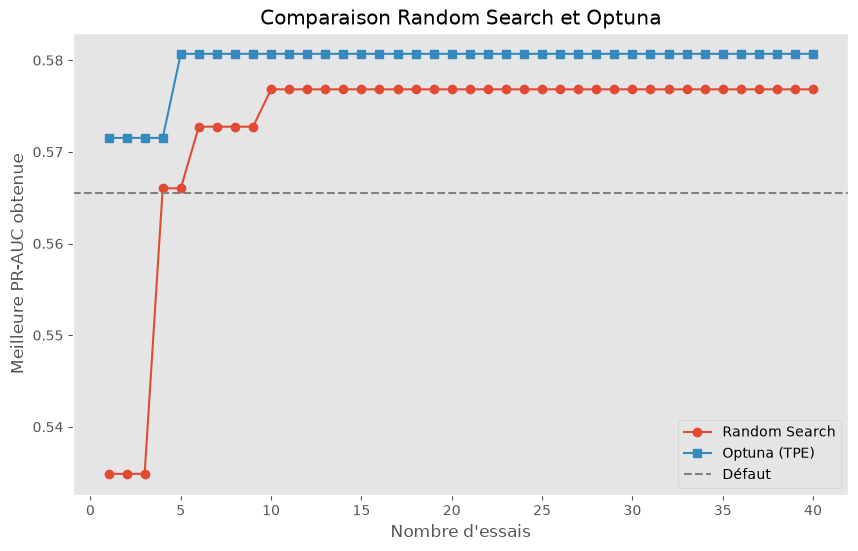

In [23]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 41),
    meilleur_rs_progressif,
    marker="o",
    label="Random Search"
)

plt.plot(
    range(1, len(meilleur_optuna_progressif) + 1),
    meilleur_optuna_progressif,
    marker="s",
    label="Optuna (TPE)"
)

plt.xlabel("Nombre d'essais")
plt.ylabel("Meilleure PR-AUC obtenue")
plt.title("Comparaison Random Search et Optuna")
plt.axhline(base_mean, ls='--', color='gray', label='Défaut')
plt.legend()
plt.grid()
plt.savefig(ROOT / 'reports' / 'figures' / 'Comparaison_Random_Search_vs_Optuna.png', dpi=150)
plt.show()

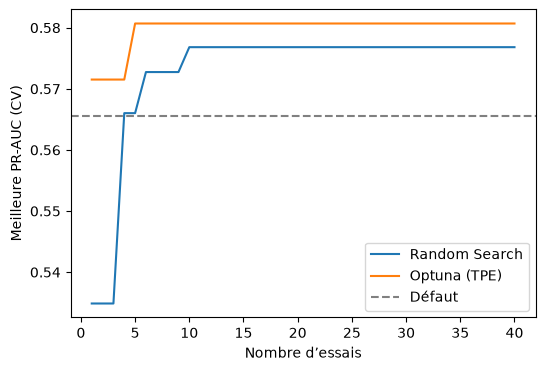

In [ ]:
##meilleur score après 1, 2, …, 40 essais
rs_cummax = np.maximum.accumulate(rs.cv_results_['mean_test_score'])
optuna_cummax = np.maximum.accumulate([t.value for t in study.trials])

plt.figure(figsize=(6, 4))
plt.plot(range(1, 41), rs_cummax, label='Random Search')
plt.plot(range(1, 41), optuna_cummax, label='Optuna (TPE)')
plt.axhline(base_mean, ls='--', color='gray', label='Défaut')
plt.xlabel('Nombre d’essais')
plt.ylabel('Meilleure PR-AUC (CV)')
plt.legend()plt.savefig(ROOT / 'reports' / 'figures' / 'optuna_vs_random.png', dpi=150)

plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_23304\1697780120.py:2: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)
C:\Users\hp\AppData\Local\Temp\ipykernel_23304\1697780120.py:4: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(study)


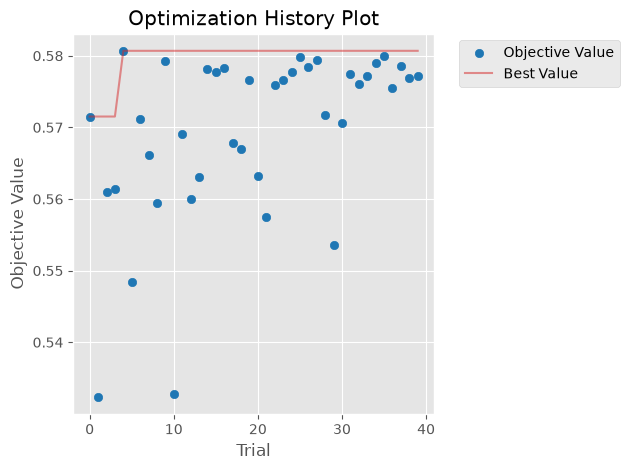

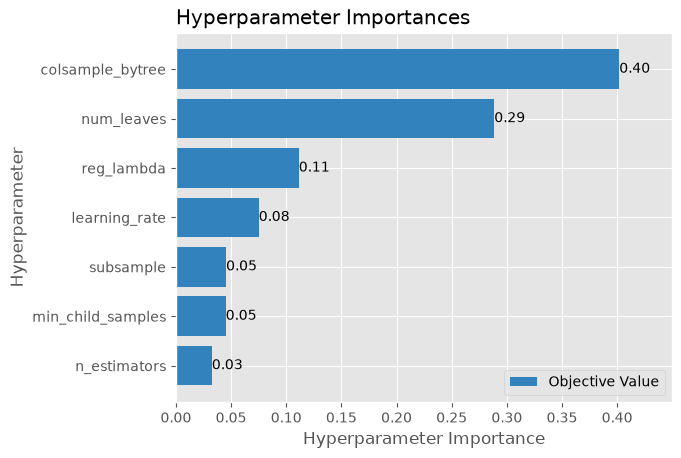

In [24]:
## importance des hyperparamètres
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.savefig(ROOT / 'reports' / 'figures' / 'optuna_optimization_history.png', dpi=150)
optuna.visualization.matplotlib.plot_param_importances(study)
plt.savefig(ROOT / 'reports' / 'figures' / 'optuna_param_importances.png', dpi=150)
plt.show()


In [10]:
params_retenus = {**study.best_params, 'subsample_freq': 1}
(ROOT / 'reports' / 'best_params.json').write_text(json.dumps(params_retenus, indent=2))
params_retenus

{'learning_rate': 0.029341527565000736,
 'num_leaves': 6,
 'min_child_samples': 45,
 'subsample': 0.5852620618436457,
 'colsample_bytree': 0.5325257964926398,
 'reg_lambda': 6.245139574743075,
 'n_estimators': 583,
 'subsample_freq': 1}